--- PUNTO 1 ---


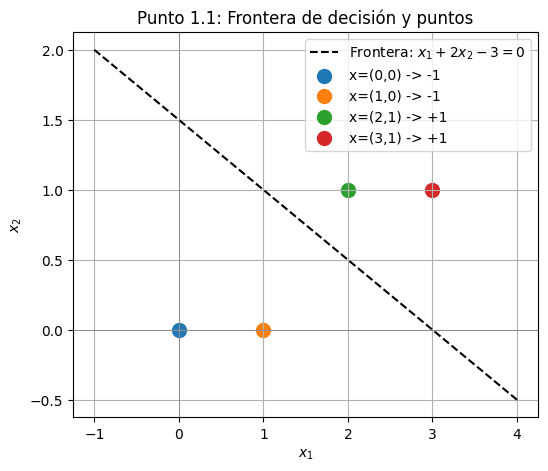

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Fijar semilla global
np.random.seed(42)

# PUNTO 1: PERCEPTRÓN Y FRONTERA DE DECISIÓN
print("--- PUNTO 1 ---")
w = np.array([1, 2])
b = -3
puntos = np.array([[0, 0], [1, 0], [2, 1], [3, 1]])

# Graficar frontera
plt.figure(figsize=(6, 5))
x1_vals = np.linspace(-1, 4, 100)
x2_vals = -(w[0] * x1_vals + b) / w[1]

plt.plot(x1_vals, x2_vals, 'k--', label=r'Frontera: $x_1 + 2x_2 - 3 = 0$')
for p in puntos:
    val = np.dot(w, p) + b
    clase = "+1" if val > 0 else "-1"
    plt.scatter(p[0], p[1], s=100, label=f'x=({p[0]},{p[1]}) -> {clase}')

plt.xlabel('$x_1$')
plt.ylabel('$x_2$')
plt.title('Punto 1.1: Frontera de decisión y puntos')
plt.axhline(0, color='gray', linewidth=0.5)
plt.axvline(0, color='gray', linewidth=0.5)
plt.legend()
plt.grid(True)
plt.show()


--- PUNTO 2 ---
k= 1 | Accuracy Train: 1.0000 | Accuracy Test: 0.9333
k= 5 | Accuracy Train: 0.9571 | Accuracy Test: 0.9556
k=15 | Accuracy Train: 0.9571 | Accuracy Test: 0.9333


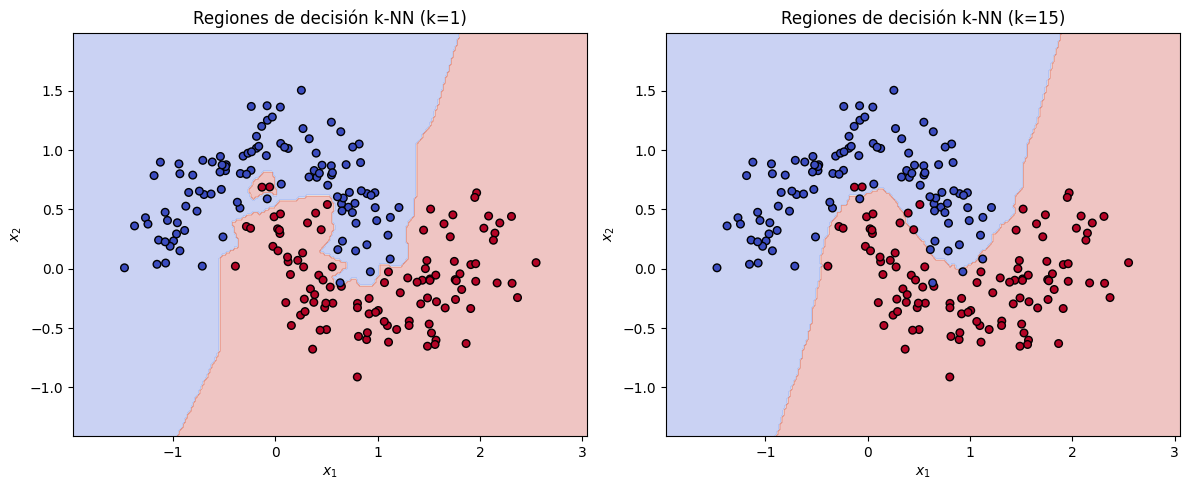

In [ ]:
# PUNTO 2: k-NN Y REGIONES DE DECISIÓN
print("\n--- PUNTO 2 ---")
# Generar datos make_moons
X, y = make_moons(n_samples=300, noise=0.20, random_state=42)

# Separación 70% train / 30% test estratificado
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

k_values = [1, 5, 15]
models = {}

for k in k_values:
    clf = KNeighborsClassifier(n_neighbors=k)
    clf.fit(X_train, y_train)
    models[k] = clf

    acc_train = clf.score(X_train, y_train)
    acc_test = clf.score(X_test, y_test)
    print(f"k={k:2d} | Accuracy Train: {acc_train:.4f} | Accuracy Test: {acc_test:.4f}")

# Gráficas de Regiones de Decisión para k=1 y k=15
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Malla para graficar regiones
x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02),
                     np.arange(y_min, y_max, 0.02))

for ax, k in zip(axes, [1, 15]):
    Z = models[k].predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    ax.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.coolwarm)
    ax.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap=plt.cm.coolwarm, edgecolors='k', s=30)
    ax.set_title(f'Regiones de decisión k-NN (k={k})')
    ax.set_xlabel('$x_1$')
    ax.set_ylabel('$x_2$')

plt.tight_layout()
plt.show()

In [ ]:
# PUNTO 3: EVALUACIÓN DE CLASIFICADOR BINARIO
print("\n--- PUNTO 3 ---")
y_real = np.array([0, 0, 0, 0, 1, 1, 1, 1, 1, 1])
y_pred = np.array([0, 1, 0, 0, 1, 0, 1, 1, 0, 1])

# Matriz de confusión
cm = confusion_matrix(y_real, y_pred)
acc = accuracy_score(y_real, y_pred)
prec = precision_score(y_real, y_pred)
rec = recall_score(y_real, y_pred)
f1 = f1_score(y_real, y_pred)

print("Matriz de Confusión [TN, FP / FN, TP]:")
print(cm)
print(f"Accuracy : {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall   : {rec:.4f}")
print(f"F1-score : {f1:.4f}")


--- PUNTO 3 ---
Matriz de Confusión [TN, FP / FN, TP]:
[[3 1]
 [2 4]]
Accuracy : 0.7000
Precision: 0.8000
Recall   : 0.6667
F1-score : 0.7273
